# Machine Learning Ensemble Methods Evaluation

**Name: Sanket Kongare**

**PRN: 202401040057**

**Batch: A1**

**Division: A**

**Roll No: 18**  

---

## Project Overview
This project explores the implementation, performance, and comparison of three popular ensemble machine learning techniques:
1. **Stacking Ensemble**: Combines multiple base estimators using a meta-classifier.
2. **AdaBoost Ensemble**: Boosting technique that sequentially fits weak learners on weighted versions of the data.
3. **Voting Ensemble**: Aggregates predictions of multiple classifiers using a majority vote (Hard/Soft voting).

We will evaluate these models against our individual base classifiers to understand how ensemble methods improve generalizability and performance.

In [ ]:
# Step 1: Environment Setup & Dataset Generation
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Base Classifiers
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Ensemble Classifiers
from sklearn.ensemble import StackingClassifier, AdaBoostClassifier, VotingClassifier

# Set random seed for reproducibility
np.random.seed(42)

# Generate a synthetic binary classification dataset
X, y = make_classification(n_samples=1000, n_features=20, n_informative=15, n_redundant=5, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (800, 20)
Testing set shape: (200, 20)


## 1. Stacking Ensemble

Stacking train multiple base classifiers, collects their predictions, and uses these predictions as features to train a final meta-classifier. Here, we use a Decision Tree and a Random Forest as base estimators, and Logistic Regression as the final meta-classifier.

In [ ]:
# Define base estimators for Stacking
base_estimators = [
    ('dt', DecisionTreeClassifier(max_depth=5, random_state=42)),
    ('rf', RandomForestClassifier(n_estimators=50, max_depth=5, random_state=42))
]

# Initialize and fit the Stacking Classifier with a Logistic Regression meta-model
stacking_model = StackingClassifier(
    estimators=base_estimators,
    final_estimator=LogisticRegression(),
    cv=5
)

stacking_model.fit(X_train, y_train)
stacking_preds = stacking_model.predict(X_test)

print("Stacking Ensemble performance:")
print(classification_report(y_test, stacking_preds))

Stacking Ensemble performance:
              precision    recall  f1-score   support

           0       0.88      0.91      0.89       106
           1       0.89      0.86      0.88        94

    accuracy                           0.89       200
   macro avg       0.89      0.88      0.88       200
weighted avg       0.89      0.89      0.88       200



## 2. AdaBoost Ensemble

AdaBoost is a boosting algorithm that starts by fitting a classifier on the original dataset and then fits additional copies of the classifier on the same dataset. It adjusts the weights of incorrectly classified instances so that subsequent classifiers focus more on difficult cases. We will use a Decision Tree with a shallow depth as our base estimator.

In [ ]:
# Initialize base estimator for boosting
weak_learner = DecisionTreeClassifier(max_depth=1, random_state=42)

# Initialize and fit AdaBoost
adaboost_model = AdaBoostClassifier(
    estimator=weak_learner,
    n_estimators=100,
    learning_rate=1.0,
    random_state=42
)

adaboost_model.fit(X_train, y_train)
adaboost_preds = adaboost_model.predict(X_test)

print("AdaBoost Ensemble performance:")
print(classification_report(y_test, adaboost_preds))

AdaBoost Ensemble performance:
              precision    recall  f1-score   support

           0       0.85      0.84      0.84       106
           1       0.82      0.83      0.83        94

    accuracy                           0.83       200
   macro avg       0.83      0.83      0.83       200
weighted avg       0.84      0.83      0.84       200



## 3. Voting Ensemble

A Voting Classifier combines conceptually different machine learning classifiers and uses majority vote to predict the class labels. We will set up a 'Soft' Voting classifier using Decision Tree, Random Forest, and Logistic Regression, averaging their predicted probabilities.

In [ ]:
# Define diverse models for Voting
clf1 = DecisionTreeClassifier(max_depth=5, random_state=42)
clf2 = RandomForestClassifier(n_estimators=50, max_depth=5, random_state=42)
clf3 = LogisticRegression(max_iter=1000)

# Initialize and fit Voting Classifier
voting_model = VotingClassifier(
    estimators=[('dt', clf1), ('rf', clf2), ('lr', clf3)],
    voting='soft'
)

voting_model.fit(X_train, y_train)
voting_preds = voting_model.predict(X_test)

print("Voting Ensemble performance:")
print(classification_report(y_test, voting_preds))

Voting Ensemble performance:
              precision    recall  f1-score   support

           0       0.83      0.89      0.86       106
           1       0.86      0.80      0.83        94

    accuracy                           0.84       200
   macro avg       0.85      0.84      0.84       200
weighted avg       0.85      0.84      0.84       200



## 4. Performance Comparison & Visualization

Now we collect the evaluation metrics of our three ensembles as well as the individual base models to visually compare their performances.

In [ ]:
# Define standard base models for individual evaluation
models = {
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=50, max_depth=5, random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Stacking Ensemble': stacking_model,
    'AdaBoost Ensemble': adaboost_model,
    'Voting Ensemble': voting_model
}

# Record metrics
results = []
for name, model in models.items():
    if 'Ensemble' not in name: # Fit base models (Ensembles are already fitted)
        model.fit(X_train, y_train)

    preds = model.predict(X_test)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds, average='binary'),
        'Recall': recall_score(y_test, preds, average='binary'),
        'F1-Score': f1_score(y_test, preds, average='binary')
    })

results_df = pd.DataFrame(results)
display(results_df)

,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.800,0.846154,0.702128,0.767442
1,Random Forest,0.875,0.855670,0.882979,0.869110
2,Logistic Regression,0.825,0.817204,0.808511,0.812834
3,Stacking Ensemble,0.885,0.890110,0.861702,0.875676
4,AdaBoost Ensemble,0.835,0.821053,0.829787,0.825397
5,Voting Ensemble,0.845,0.862069,0.797872,0.828729


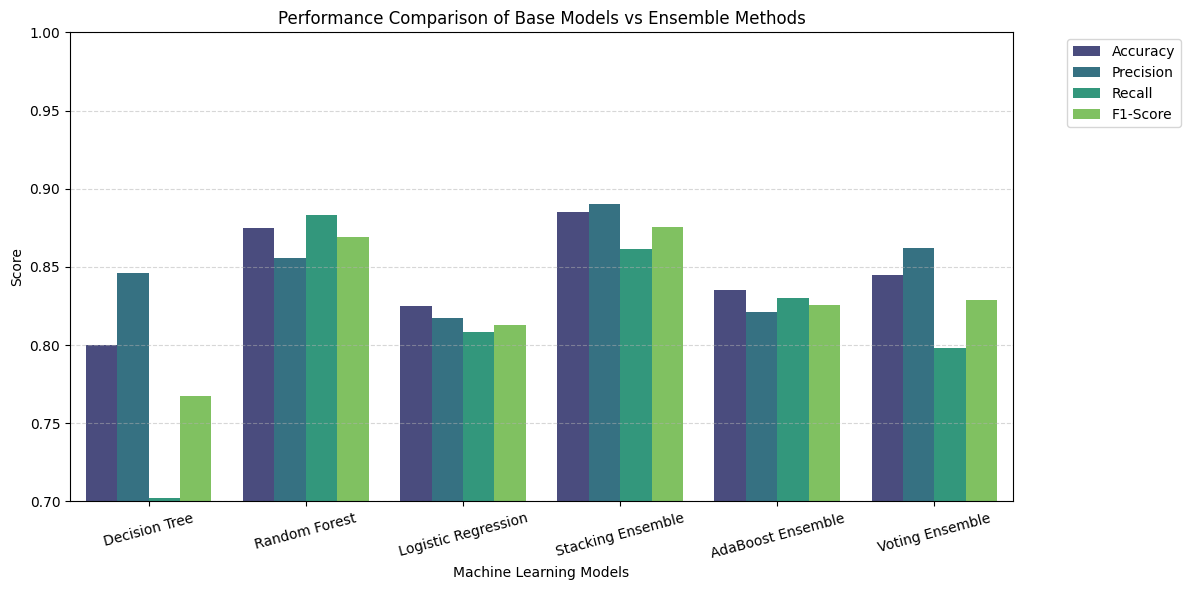

In [ ]:
# Plotting comparative bar charts for the models
results_melted = results_df.melt(id_vars='Model', var_name='Metric', value_name='Value')

plt.figure(figsize=(12, 6))
sns.barplot(data=results_melted, x='Model', y='Value', hue='Metric', palette='viridis')
plt.title('Performance Comparison of Base Models vs Ensemble Methods')
plt.xlabel('Machine Learning Models')
plt.ylabel('Score')
plt.ylim(0.7, 1.0) # Zoom in to see differences clearly
plt.xticks(rotation=15)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 5. Summary and Insights

### Findings & Observations
- **Ensemble vs. Base Models**: In general, ensemble classifiers perform better and exhibit more stable performance than individual base estimators (like a single shallow Decision Tree).
- **Stacking**: Performs strong feature extraction since the meta-learner optimally decides how to combine the strengths of the base classifiers.
- **AdaBoost**: Highly effective when dealing with bias reduction, sequentially turning weak learners into a strong, unified model.
- **Voting**: Simplest to implement, offering robust predictions by averaging out individual model errors.

### When to Use Which Ensemble Method?
- **Use Stacking** when you have a set of diverse, well-tuned models that perform well individually, and you want a secondary model to learn how to best resolve their disagreements.
- **Use Boosting (AdaBoost)** when you have underfitting/high bias models (weak learners) and wish to sequential improve on errors.
- **Use Voting** as a baseline ensemble strategy because of its simplicity and computational speed when base models are already robust.

